<a href="https://colab.research.google.com/github/Jiayi-Eva-Wang/Problem-Set-1-Econ_3916_PS1.ipynb/blob/main/Problem%20Set%201/Econ_3916_PS1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS1 — The Cost of Living Brief

**Starter notebook.** The Canvas assignment is the brief: read it first. This
notebook only gives you the structure, one heading per step in the order the
rubric grades them. Every cell that computes something is yours to write.

**Before you start**
1. *File › Save a copy in Drive*, and rename the copy `Econ 3916 PS1`.
2. Write every explanation in a **text cell**, not in `#` comments. A client
   reads this as a document.
3. **AI is not allowed in Phases 1–3.** You write the dictionaries, the loops,
   the data fetches and the interpretation yourself. Phase 4 is where AI is
   required.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

---
## Phase 1: Construct the Basket (30 pts)

### Step 1.1: Define the household (20 pts)

**Who is the household?** Describe one concrete household in a sentence or two:
who earns, how they get to work, what they spend on. Every later choice has to
be defensible for them.

Household: A married couple in Boston owns a paid-off house and dines out three to four times a week. The husband works full-time and commutes by car.

> ### New idiom — a list of dictionaries
>
> A **dictionary** holds values under names: `{"Item": "Rent", "weight": 0.35}`.
> `item["weight"]` reads a value back by its name.
>
> A **list of dictionaries** is one dictionary per row, in square brackets and
> separated by commas. It is how you store a small table by hand:
>
> ```python
> fruit = [
>     {"name": "apple",  "price": 0.50},
>     {"name": "banana", "price": 0.25},
> ]
> for f in fruit:            # f is one dictionary at a time
>     print(f["name"], f["price"])
> ```
>
> Use the keys `Item`, `Price_2019`, `Price_2024` and `weight`: the Phase 4
> prompt assumes those names.

In [ ]:
# At least six categories. Weights are shares of monthly spending and must sum to 1.0.

household_basket = [
    {"Item": "Groceries", "Price_2019": 600, "Price_2024": 750, "weight": 600 / 3000},
    {"Item": "Dining out", "Price_2019": 1000, "Price_2024": 1500, "weight": 1000 / 3000},
    {"Item": "Gasoline", "Price_2019": 150, "Price_2024": 180, "weight": 150 / 3000},
    {"Item": "Car insurance", "Price_2019": 150, "Price_2024": 210, "weight": 150 / 3000},
    {"Item": "Utilities", "Price_2019": 200, "Price_2024": 260, "weight": 200 / 3000},
    {"Item": "Home maintenance", "Price_2019": 250, "Price_2024": 325, "weight": 250 / 3000},
    {"Item": "Recreation", "Price_2019": 500, "Price_2024": 600, "weight": 500 / 3000},
    {"Item": "Home insurance", "Price_2019": 150, "Price_2024": 195, "weight": 150 / 3000}
]

In [ ]:
# Check: run this after filling in the basket
total_weight = sum(item["weight"] for item in household_basket)
print(f"{len(household_basket)} categories, weights sum to {total_weight:.4f}")

8 categories, weights sum to 1.0000


### Step 1.2: Build the index by hand (10 pts)

> ### New idiom — writing a function
>
> ```python
> def price_change(old, new):
>     """Percentage change from old to new."""
>     return (new - old) / old * 100
>
> price_change(2.00, 2.50)     # 25.0
> ```
>
> `def` names the function and its **parameters** (`old`, `new`). The body is
> indented. `return` hands the result back; without it the function gives back
> `None`. Inside the body, use the parameters, never the names of your own
> variables outside it, or the function only works on one dataset.

In [ ]:
def laspeyres(basket, base_key, current_key):
    total = 0
    for item in basket:
        price_ratio = item[current_key] / item[base_key]
        total = total + price_ratio * item["weight"]
    return total * 100

In [ ]:
unweighted_change = 0

for item in household_basket:
    change = (item["Price_2024"] / item["Price_2019"] - 1) * 100
    unweighted_change = unweighted_change + change

unweighted_change = unweighted_change / len(household_basket)

weighted_index = laspeyres(
    household_basket, "Price_2019", "Price_2024"
)
weighted_change = weighted_index - 100

gap = weighted_change - unweighted_change

print(f"Unweighted average price change: {unweighted_change:.2f}%")
print(f"Weighted Laspeyres index: {weighted_index:.2f}")
print(f"Weighted price change: {weighted_change:.2f}%")
print(f"Gap: {gap:.2f} percentage points")

Unweighted average price change: 30.62%
Weighted Laspeyres index: 134.00
Weighted price change: 34.00%
Gap: 3.38 percentage points


**Why do the two differ, and which would you defend to the client?**

The unweighted average treats all eight categories equally, while the weighted index uses their shares of 2019 spending as weights. For example, dining out has a large spending share and a high price increase, making the weighted increase higher. So I would defend the weighted price change because it better reflects this household’s spending priorities or pattern.

However, the prices are all hypothetical, so the result only illustrates this household scenario rather than actual cost increases for other Boston workers.

---
## Phase 2: Bring in the Official Series (25 pts)

### Step 2.1: Find honest proxies (15 pts)

Fetch at least these four from FRED, plus any your household needs. Lab 2
showed how to read a FRED series from its CSV link, with no API key.

In [ ]:
series_ids = ["CPIAUCSL", "CUSR0000SEHA", "CUSR0000SAF11", "CUSR0000SETA02", "CUSR0000SEFV", "CUSR0000SETB01"]

In [ ]:
import pandas as pd
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=" + series_ids[0]
cpi = pd.read_csv(url)

print(cpi.head())


fred_series = {}

for series_id in series_ids:
    url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=" + series_id
    data = pd.read_csv(url, na_values=".")

    data["observation_date"] = pd.to_datetime(data["observation_date"])
    data = data.set_index("observation_date")

    fred_series[series_id] = pd.to_numeric(data[series_id])

print(fred_series["CPIAUCSL"].head())
print("Number of series:", len(fred_series))

  observation_date  CPIAUCSL
0       1947-01-01     21.48
1       1947-02-01     21.62
2       1947-03-01     22.00
3       1947-04-01     22.00
4       1947-05-01     21.95
observation_date
1947-01-01    21.48
1947-02-01    21.62
1947-03-01    22.00
1947-04-01    22.00
1947-05-01    21.95
Name: CPIAUCSL, dtype: float64
Number of series: 6


| Series | Why it is a fair proxy for my household | What it fails to capture |
|---|---|---|
Name: All Items in U.S. City Average
| `CPIAUCSL` |It provides a benchmark for overall consumer prices in the United States, allowing comparison with the household index. |It cannot accurately reflect this couple’s spending weights and the local price in Boston.|
Name: Rent of Primary Residence in U.S. City Average
| `CUSR0000SEHA` |It provides a reference for changes in rental housing costs, which can be compared with this household’s housing expenses.| This couple owns a paid-off home, so rent does not directly represent their housing expenses, such as maintenance and home insurance. |
Name: Food at Home in U.S. City Average
| `CUSR0000SAF11` |This series tracks changes in grocery prices, making it relevant to the food this couple buys to cook at home. |It reflects average prices across U.S. cities rather than this couple’s specific grocery purchases or local prices in Boston. It also excludes dining out. |
Name: Used Cars and Trucks in U.S. City Average
| `CUSR0000SETA02` |It provides a reference for used-car market price changes if the couple wants to buy another used car or sell their current car in the future. |They currently have no car purchase expenses. This indicator does not capture gasoline, insurance, or maintenance costs. It also cannot predict the purchase price or resale value of a specific car model. |
Name: Food Away from Home in U.S. City Average
| `CUSR0000SEFV`|The couple dines out three to four times a week, so this series can reflect price changes in one of their major spending categories.| It includes various types of meals away from home and cannot accurately represent the Boston restaurants they always visit, the dishes they order, or the amount of tips they pay.|
Name: Gasoline (All Types) in U.S. City Average
| `CUSR0000SETB01`|In this scene, the husband commutes by car, so changes in gasoline prices affect the household’s transportation expenses.|It can only reflects average gasoline prices across U.S. cities rather than the specific prices they pay in Boston, which may vary with local taxes and the gasoline grade their car uses.|


### Step 2.2: Put them on the same footing (10 pts)

Rebase every series to 2019 = 100 and plot them on one chart with your
household index. The chart needs axis labels, a legend, and a title that states
a finding rather than naming the variables.

In [ ]:
# Rebase to 2019 = 100

rebased_series = {}

for series_id in series_ids:
    series = fred_series[series_id]
    base_2019 = series.loc["2019"].mean()
    rebased_series[series_id] = series / base_2019 * 100

print(rebased_series["CPIAUCSL"].loc["2019"].mean())
print(rebased_series["CPIAUCSL"].loc["2024"].mean())



100.0
122.70486868409637


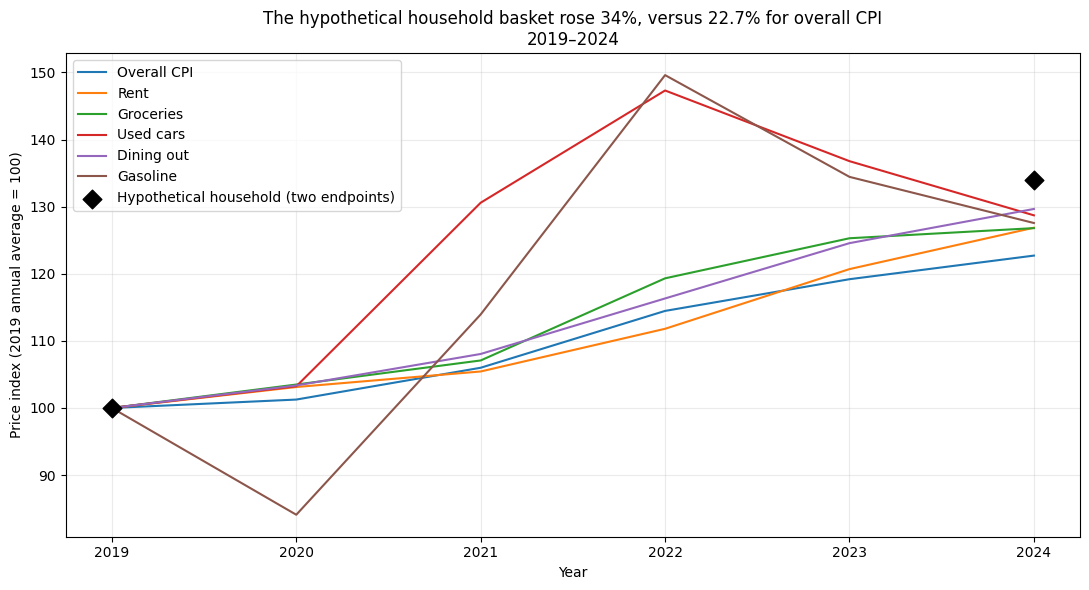

In [ ]:
# One chart: every rebased series, plus your household index

series_names = {
    "CPIAUCSL": "Overall CPI",
    "CUSR0000SEHA": "Rent",
    "CUSR0000SAF11": "Groceries",
    "CUSR0000SETA02": "Used cars",
    "CUSR0000SEFV": "Dining out",
    "CUSR0000SETB01": "Gasoline"
}

plt.figure(figsize=(11, 6))

for series_id in series_ids:
    series = rebased_series[series_id].loc["2019":"2024"]
    annual_average = series.groupby(series.index.year).mean()
    plt.plot(
        annual_average.index,
        annual_average.values,
        label=series_names[series_id]
    )

plt.scatter(
    [2019, 2024],
    [100, weighted_index],
    color="black",
    marker="D",
    s=90,
    label="Hypothetical household (two endpoints)",
    zorder=5
)

plt.title(
    "The hypothetical household basket rose 34%, versus 22.7% for overall CPI\n"
    "2019–2024"
)
plt.xlabel("Year")
plt.ylabel("Price index (2019 annual average = 100)")
plt.xticks(range(2019, 2025))
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

#The official series are shown as annual averages, rebased to 2019 = 100.
#The hypothetical household prices represent fixed spending bundles at assumed annual-average prices in 2019 and 2024.
#Only these two household observations are plotted; no intermediate values are assumed.


---
## Phase 3: What the Series Will and Will Not Let You Compare (20 pts)

### Step 3.1: Audit before you analyse (6 pts)

> ### A tool you have not used yet — a regular monthly grid
>
> `s.asfreq("MS")` puts a date-indexed series on one row per month (`"MS"` =
> month start). Any month the series skipped appears as a missing value, so
> `s.asfreq("MS").isna().sum()` counts the gaps. Report the count whatever it
> is; if it is not zero, list the missing months.

In [ ]:
# First observation, last observation, frequency and missing months, for every series

audit_rows = []

for series_id in series_ids:
    series = fred_series[series_id]
    observed = series.dropna()

    start = observed.index.min()
    end = observed.index.max()

    regular_series = series.asfreq("MS")
    missing_months = regular_series.index[regular_series.isna()]

    audit_rows.append({
        "Series": series_id,
        "First observation": start.strftime("%Y-%m"),
        "Last observation": end.strftime("%Y-%m"),
        "Frequency": "Monthly",
        "Missing months": len(missing_months),
        "Missing dates": ", ".join(missing_months.strftime("%Y-%m"))
                         if len(missing_months) else "None"
    })

audit_table = pd.DataFrame(audit_rows)
display(audit_table)


,Series,First observation,Last observation,Frequency,Missing months,Missing dates
0,CPIAUCSL,1947-01,2026-08,Monthly,1,2025-10
1,CUSR0000SEHA,1981-01,2026-08,Monthly,1,2025-10
2,CUSR0000SAF11,1952-01,2026-08,Monthly,1,2025-10
3,CUSR0000SETA02,1953-01,2026-08,Monthly,0,None
4,CUSR0000SEFV,1953-01,2026-08,Monthly,1,2025-10
5,CUSR0000SETB01,1967-01,2026-08,Monthly,0,None



All six series are monthly. CPIAUCSL, CUSR0000SEHA, CUSR0000SAF11, and CUSR0000SEFV each have one missing month: October 2025. CUSR0000SETA02 and CUSR0000SETB01 have zero missing months within their own observed histories.

According to the BLS explanation, the 2025 government shutdown interrupted October CPI data collection.
I will retain missing values without filling them. They do not affect the 2019–2024 comparison. For comparisons requiring matched observations across all series, I will exclude October 2025 from every series and leave gaps visible in monthly plots.

### Step 3.2: The sample you actually have (8 pts)

Report three numbers: when the common sample starts, how many months long it
is, and how many months of your longest series it discards. Then compute your
headline comparison twice: over each series' full history, and over the common
sample only.

In [ ]:
# Start dates side by side, and the common sample

start_dates = []

for series_id in series_ids:
    series = fred_series[series_id]

all_series = pd.DataFrame(fred_series).asfreq("MS")

start_dates = all_series.apply(lambda s: s.first_valid_index())
print("Start dates:")
print(start_dates.dt.strftime("%Y-%m").to_string())

common_start = start_dates.max()
common_end = all_series.apply(lambda s: s.last_valid_index()).min()

common_grid = all_series.loc[common_start:common_end]
common_sample = common_grid.dropna()

longest_id = start_dates.idxmin()
longest_months = all_series[longest_id].notna().sum()
discarded_months = longest_months - len(common_sample)

print("\nCommon sample starts:", common_start.strftime("%Y-%m"))
print("Common sample ends:", common_end.strftime("%Y-%m"))
print("Calendar months in common range:", len(common_grid))
print("Months with data for every series:", len(common_sample))
print("Longest series:", longest_id)
print("Observed months discarded:", discarded_months)

Start dates:
CPIAUCSL          1947-01
CUSR0000SEHA      1981-01
CUSR0000SAF11     1952-01
CUSR0000SETA02    1953-01
CUSR0000SEFV      1953-01
CUSR0000SETB01    1967-01

Common sample starts: 1981-01
Common sample ends: 2026-08
Calendar months in common range: 548
Months with data for every series: 547
Longest series: CPIAUCSL
Observed months discarded: 408


In [ ]:
# Headline comparison: full history vs common sample

comparison_rows = []

for series_id in series_ids:
    own_series = fred_series[series_id]
    common_series = common_sample[series_id]

    own_change = (
        own_series.loc["2024"].mean()
        / own_series.loc["2019"].mean() - 1
    ) * 100

    common_change = (
        common_series.loc["2024"].mean()
        / common_series.loc["2019"].mean() - 1
    ) * 100

    comparison_rows.append({
        "Series": series_id,
        "Own-history change (%)": own_change,
        "Common-sample change (%)": common_change,
        "Difference (percentage points)": common_change - own_change
    })

comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table.round(2))

own_cpi_change = comparison_table.loc[
    comparison_table["Series"] == "CPIAUCSL",
    "Own-history change (%)"
].iloc[0]

common_cpi_change = comparison_table.loc[
    comparison_table["Series"] == "CPIAUCSL",
    "Common-sample change (%)"
].iloc[0]

print(f"Household minus CPI, own history: {weighted_change - own_cpi_change:.2f} percentage points")
print(f"Household minus CPI, common sample: {weighted_change - common_cpi_change:.2f} percentage points")

,Series,Own-history change (%),Common-sample change (%),Difference (percentage points)
0,CPIAUCSL,22.70,22.70,0.0
1,CUSR0000SEHA,26.86,26.86,0.0
2,CUSR0000SAF11,26.80,26.80,0.0
3,CUSR0000SETA02,28.70,28.70,0.0
4,CUSR0000SEFV,29.65,29.65,0.0
5,CUSR0000SETB01,27.56,27.56,0.0


Household minus CPI, own history: 11.30 percentage points
Household minus CPI, common sample: 11.30 percentage points


**What restricting to the common sample assumes, and what not restricting assumes:**

The common sample starts in January 1981 and includes 547 months with data for all six series, excluding 408 months of observed data from the CPI series.

Restricting to the common sample assumes that the shared period provides enough information to answer the client’s question, even though earlier observations are discarded. Comparing statistics over each series’ full history would assume that differences in historical coverage do not distort the comparison.

In this analysis, both approaches use the same complete 2019–2024 observations, so the results are the same, yielding a CPI increase of 22.70% and a household-CPI gap of 11.30 percentage points. I would present the common-sample result to the client and report that the sample restriction changes the household–CPI gap by zero percentage points.

### Step 3.3: Somebody already made a decision for you (6 pts)

Pull the unadjusted twin of one series (`CPIAUCNS`, `CUUR0000SEHA`,
`CUUR0000SAF11` or `CUUR0000SETA02`) and plot the pair over the last five years.

Series: CPIAUCNS
First observation: 1913-01
Last observation: 2026-08
Frequency: Monthly
Missing months: 1
Missing dates: ['2025-10']


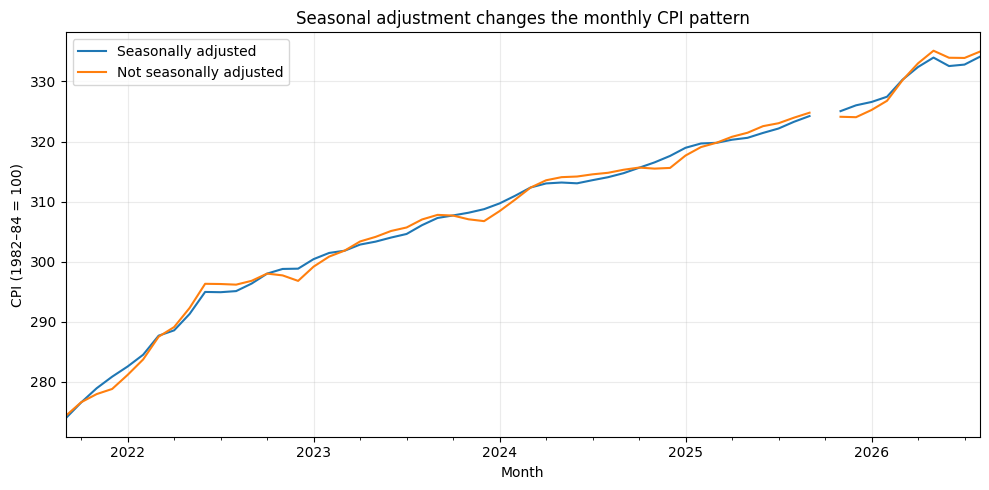

In [ ]:
# Seasonally adjusted vs unadjusted, last five years

series_id = "CPIAUCNS"
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=" + series_id

data = pd.read_csv(url, na_values=".")
data["observation_date"] = pd.to_datetime(data["observation_date"])
data = data.set_index("observation_date")
unadjusted = pd.to_numeric(data[series_id])

start = unadjusted.first_valid_index()
end = unadjusted.last_valid_index()
regular = unadjusted.loc[start:end].asfreq("MS")
missing = regular.index[regular.isna()]

print("Series:", series_id)
print("First observation:", start.strftime("%Y-%m"))
print("Last observation:", end.strftime("%Y-%m"))
print("Frequency: Monthly")
print("Missing months:", len(missing))
print("Missing dates:", list(missing.strftime("%Y-%m")))

pair = pd.DataFrame({
    "Seasonally adjusted": fred_series["CPIAUCSL"],
    "Not seasonally adjusted": unadjusted
}).asfreq("MS")

plot_end = min(
    fred_series["CPIAUCSL"].last_valid_index(),
    unadjusted.last_valid_index()
)
plot_start = plot_end - pd.DateOffset(months=59)

pair.loc[plot_start:plot_end].plot(figsize=(10, 5))
plt.title("Seasonal adjustment changes the monthly CPI pattern")
plt.xlabel("Month")
plt.ylabel("CPI (1982–84 = 100)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**What does the gap between the two lines consist of? Which series belongs in this brief, and why?**

*Your answer here: The gap consists of the seasonal component estimated and removed by BLS’s adjustment model. The unadjusted CPIAUCNS belongs in this brief because it retains seasonal price changes that workers actually face. I used CPIAUCSL earlier to compare price trends using the assignment’s specified benchmark.

---
## Phase 4: AI Expansion (25 pts)

AI is now allowed and required.

### Task 4.1: The sensitivity surface (15 pts)

Run the P.R.I.M.E. prompt from the brief, then paste the code below and run it.

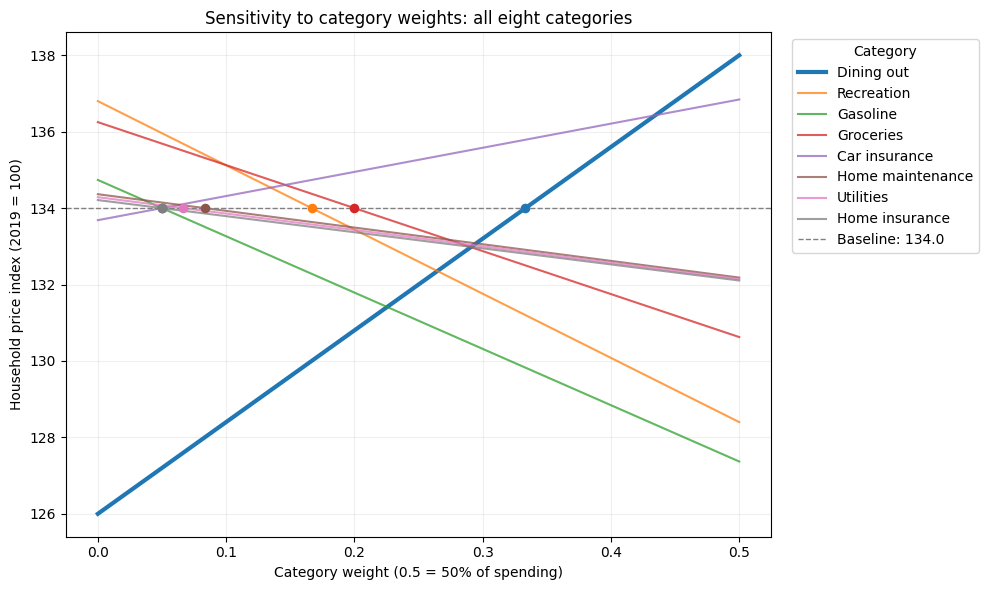

Baseline index: 134.0
            Item  Index_at_weight_0  Index_at_weight_0.5  Range_index_points
      Dining out             126.00               138.00               12.00
      Recreation             136.80               128.40                8.40
        Gasoline             134.74               127.37                7.37
       Groceries             136.25               130.62                5.62
   Car insurance             133.68               136.84                3.16
Home maintenance             134.36               132.18                2.18
       Utilities             134.29               132.14                2.14
  Home insurance             134.21               132.11                2.11


In [ ]:
# Paste the AI's code here, run it, and correct it where it is wrong

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

basket = pd.DataFrame(household_basket)

weights = basket["weight"].to_numpy(dtype=float)
weights = weights / weights.sum()
price_relatives = (
    basket["Price_2024"] / basket["Price_2019"]
).to_numpy(dtype=float)

baseline_index = 100 * np.dot(weights, price_relatives)
weight_grid = np.linspace(0, 0.5, 101)

results = []
sensitivity = []

for i, item in enumerate(basket["Item"]):
    other_mask = np.arange(len(basket)) != i

    # All weights must sum to 1. When this category gets weight x,
    # the others must share 1-x, preserving their original proportions.
    other_proportions = (
        weights[other_mask] / weights[other_mask].sum()
    )

    indices = []

    for new_weight in weight_grid:
        adjusted_weights = np.zeros_like(weights)
        adjusted_weights[i] = new_weight
        adjusted_weights[other_mask] = (
            (1 - new_weight) * other_proportions
        )

        index = 100 * np.dot(adjusted_weights, price_relatives)
        indices.append(index)
        results.append({
            "Item": item,
            "weight": new_weight,
            "index": index
        })

    # A large range means the index depends strongly on this category's
    # budget share. Its price change differs substantially from the
    # weighted price changes of the remaining categories.
    sensitivity.append({
        "Item": item,
        "Index_at_weight_0": indices[0],
        "Index_at_weight_0.5": indices[-1],
        "Range_index_points": np.ptp(indices)
    })

results = pd.DataFrame(results)
sensitivity = (
    pd.DataFrame(sensitivity)
    .sort_values("Range_index_points", ascending=False)
    .reset_index(drop=True)
)

dominant_item = sensitivity.loc[0, "Item"]

fig, ax = plt.subplots(figsize=(10, 6))

for item in sensitivity["Item"]:
    series = results.loc[results["Item"] == item]
    dominant = item == dominant_item

    line, = ax.plot(
        series["weight"],
        series["index"],
        label=item,
        linewidth=3 if dominant else 1.5,
        alpha=1 if dominant else 0.75
    )

    original_position = basket.index[basket["Item"] == item][0]
    ax.scatter(
        weights[original_position],
        baseline_index,
        color=line.get_color(),
        s=35,
        zorder=3
    )

ax.axhline(
    baseline_index,
    color="gray",
    linestyle="--",
    linewidth=1,
    label=f"Baseline: {baseline_index:.1f}"
)

ax.set(
    xlabel="Category weight (0.5 = 50% of spending)",
    ylabel="Household price index (2019 = 100)",
    title="Sensitivity to category weights: all eight categories"
)
ax.grid(alpha=0.2)
ax.legend(title="Category", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()

print(f"Baseline index: {baseline_index:.1f}")
print(sensitivity.round(2).to_string(index=False))

In [ ]:
checks = []

for i, item in enumerate(basket["Item"]):
    other_mask = np.arange(len(weights)) != i
    proportions = weights[other_mask] / weights[other_mask].sum()

    for x in weight_grid:
        test_weights = np.zeros_like(weights)
        test_weights[i] = x
        test_weights[other_mask] = (1 - x) * proportions

        assert np.isclose(test_weights.sum(), 1)
        assert np.all(test_weights >= 0)

    original_weights = np.zeros_like(weights)
    original_weights[i] = weights[i]
    original_weights[other_mask] = (1 - weights[i]) * proportions
    restored_index = 100 * np.dot(original_weights, price_relatives)

    assert np.allclose(original_weights, weights)
    assert np.isclose(restored_index, weighted_index)

    checks.append({"Item": item, "Restored index": restored_index})

display(pd.DataFrame(checks))
print("All weight-sum, nonnegative-weight, and baseline checks passed.")

dining_check = 100 * (
    0.5 * 1.5 + 0.5 * (2520 / 2000)
)
print("Independent dining-out check at weight 0.5:", dining_check)

,Item,Restored index
0,Groceries,134.0
1,Dining out,134.0
2,Gasoline,134.0
3,Car insurance,134.0
4,Utilities,134.0
5,Home maintenance,134.0
6,Recreation,134.0
7,Home insurance,134.0


All weight-sum, nonnegative-weight, and baseline checks passed.
Independent dining-out check at weight 0.5: 138.0


**What did the model get wrong, or get right in a way you had to check? Show the check.**

*Your answer here：The model correctly handled all eight categories. I found no calculation errors. The checks confirmed that weights sum to one, original weights reproduce the index of 134, and a 50% dining-out weight gives 138.

### AI Transcript

**Model: ChatGPT &nbsp; **Date: 2026 Oct 10

*Paste the prompt exactly as you sent it, then the model's reply exactly as it
came back, before your corrections.*

**Prompt**: Hi! My basket contains eight categories. Please use all eight.

household_basket = [
    {"Item": "Groceries", "Price_2019": 600, "Price_2024": 750, "weight": 600 / 3000},
    {"Item": "Dining out", "Price_2019": 1000, "Price_2024": 1500, "weight": 1000 / 3000},
    {"Item": "Gasoline", "Price_2019": 150, "Price_2024": 180, "weight": 150 / 3000},
    {"Item": "Car insurance", "Price_2019": 150, "Price_2024": 210, "weight": 150 / 3000},
    {"Item": "Utilities", "Price_2019": 200, "Price_2024": 260, "weight": 200 / 3000},
    {"Item": "Home maintenance", "Price_2019": 250, "Price_2024": 325, "weight": 250 / 3000},
    {"Item": "Recreation", "Price_2019": 500, "Price_2024": 600, "weight": 500 / 3000},
    {"Item": "Home insurance", "Price_2019": 150, "Price_2024": 195, "weight": 150 / 3000}
]

[Prep] Act as an applied economist who builds reproducible analysis for client deliverables.
[Request] I have a household price index built as a weighted Laspeyres over six spending categories, in a list of dicts named household_basket with keys Item, Price_2019, Price_2024 and weight. Write Python that sweeps each category’s weight from 0 to 0.5, holding the others in proportion, recomputes the index, and produces a single chart showing which category’s weight the result is most sensitive to.
[Iterate] numpy, pandas and matplotlib only. Reuse my variable names. No deprecated matplotlib arguments.
[Mechanism Check] Add comments explaining why renormalising the other weights is necessary, and what it would mean if the index were highly sensitive to a single category.
[Evaluate] Tell me which category dominates my result and what I should say to a client about it.

**Reply:**

Using all eight categories, your baseline index is 134.0 (2019 = 100), representing 34% cumulative inflation.
Run this after your existing household_basket definition:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

basket = pd.DataFrame(household_basket)

weights = basket["weight"].to_numpy(dtype=float)
weights = weights / weights.sum()
price_relatives = (
    basket["Price_2024"] / basket["Price_2019"]
).to_numpy(dtype=float)

baseline_index = 100 * np.dot(weights, price_relatives)
weight_grid = np.linspace(0, 0.5, 101)

results = []
sensitivity = []

for i, item in enumerate(basket["Item"]):
    other_mask = np.arange(len(basket)) != i

    # All weights must sum to 1. When this category gets weight x,
    # the others must share 1-x, preserving their original proportions.
    other_proportions = (
        weights[other_mask] / weights[other_mask].sum()
    )

    indices = []

    for new_weight in weight_grid:
        adjusted_weights = np.zeros_like(weights)
        adjusted_weights[i] = new_weight
        adjusted_weights[other_mask] = (
            (1 - new_weight) * other_proportions
        )

        index = 100 * np.dot(adjusted_weights, price_relatives)
        indices.append(index)
        results.append({
            "Item": item,
            "weight": new_weight,
            "index": index
        })

    # A large range means the index depends strongly on this category's
    # budget share. Its price change differs substantially from the
    # weighted price changes of the remaining categories.
    sensitivity.append({
        "Item": item,
        "Index_at_weight_0": indices[0],
        "Index_at_weight_0.5": indices[-1],
        "Range_index_points": np.ptp(indices)
    })

results = pd.DataFrame(results)
sensitivity = (
    pd.DataFrame(sensitivity)
    .sort_values("Range_index_points", ascending=False)
    .reset_index(drop=True)
)

dominant_item = sensitivity.loc[0, "Item"]

fig, ax = plt.subplots(figsize=(10, 6))

for item in sensitivity["Item"]:
    series = results.loc[results["Item"] == item]
    dominant = item == dominant_item

    line, = ax.plot(
        series["weight"],
        series["index"],
        label=item,
        linewidth=3 if dominant else 1.5,
        alpha=1 if dominant else 0.75
    )

    original_position = basket.index[basket["Item"] == item][0]
    ax.scatter(
        weights[original_position],
        baseline_index,
        color=line.get_color(),
        s=35,
        zorder=3
    )

ax.axhline(
    baseline_index,
    color="gray",
    linestyle="--",
    linewidth=1,
    label=f"Baseline: {baseline_index:.1f}"
)

ax.set(
    xlabel="Category weight (0.5 = 50% of spending)",
    ylabel="Household price index (2019 = 100)",
    title="Sensitivity to category weights: all eight categories"
)
ax.grid(alpha=0.2)
ax.legend(title="Category", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()

print(f"Baseline index: {baseline_index:.1f}")
print(sensitivity.round(2).to_string(index=False))

Dining out dominates the sensitivity: sweeping its weight from 0% to 50% moves the index from 126 to 138, a 12-point range, the largest of the eight categories. It also contributes the most to baseline inflation: 16.67 of the 34 percentage points, because its prices increased 50% and its original budget share is one-third.
For a client, say: “The household’s estimated cumulative inflation is 34%, with dining out accounting for nearly half of that increase. The estimate is most sensitive to the dining-out budget share, so we should verify that share reflects the household’s actual 2019 spending. This measures a fixed-basket price increase; it does not capture subsequent changes in spending habits.”

### Task 4.2: The written finding (10 pts)

250 words at most, to the director. A number in the first sentence, no code,
and a confidence level.

Our hypothetical household basket rose 34% between 2019 and 2024, compared with 22.7% for the seasonally adjusted national CPI, a difference of 11.3 percentage points. This scenario does not support the client’s claim that CPI necessarily overstates workers’ price increases.

This household is a married couple in Boston with a paid-off home, a car commute, and frequent restaurant meals. Dining out accounts for one-third of the assumed 2019 budget and contributes 16.67 percentage points to the total increase. Changing its budget share from zero to 50%, while keeping other shares proportional, will change the estimated increase from 26% to 38%.

I have high confidence in the calculations but low confidence that this scenario represents the employer’s workers. Because prices are hypothetical, the basket omits some expenses, and national price series do not capture every Boston household’s experience. Restricting the official data to the common sample leaves the 2019–2024 comparison unchanged.

The client should use CPI as a reference and collect employees’ actual spending shares and comparable local prices before deciding on a starting-wage increase. For a brief about prices workers actually pay, I would prefer the unadjusted CPI and clearly label the adjusted benchmark used here.

*Your finding here.*

---
### Before you submit
- [✅] Every step above has output, and every explanation is in a text cell
- [✅] The AI Transcript names the model and the date
- [✅] *Runtime › Restart and run all* runs without errors
- [ ] Share link on Canvas; the same notebook in `Problem Set 1/` on GitHub